In [1]:
import random
import time

import numpy as np
import pandas as pd
import ptwt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (
    auc,
    roc_curve,
)
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import DataLoader, Dataset
from torchmetrics.classification import BinaryROC
import matplotlib.pyplot as plt

/home/assalim/Desktop/Master/A-Wavelet-Based-Convolutional-Neural-Network-for-Deepfake-Audio-Detection/venv/lib/python3.13/site-packages/librosa/util/files.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


In [2]:
EPOCHS = 100
BATCH_SIZE = 32
SEED = 42
WAVELET_FAMILIES = ["db4", "db6", "db8", "db14", "db16", "db18", "db24", "db26", "db28", "db34", "db36", "db38"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

random.seed(SEED)
torch.manual_seed(SEED)
np.random.seed(SEED)

cuda


In [5]:
def load_split(name):
    X = np.load(f"../Data/{name}_features.npy", mmap_mode="r")
    meta = pd.read_csv(f"../Data/{name}_meta.csv")

    X = np.asarray(X, dtype=np.float32).reshape(X.shape[0], -1, X.shape[-1])
    y = meta["is_bonafide"].to_numpy().astype(np.int64)

    return X, y, meta

In [6]:
t0 = time.time()
X_train, y_train, train_meta = load_split("train")
X_dev, y_dev, dev_meta = load_split("dev")
X_eval, y_eval, eval_meta = load_split("eval")
print(f"{time.time() - t0:.1f}s | train {X_train.shape} | dev {X_dev.shape} | eval {X_eval.shape}")

16.2s | train (25380, 40, 401) | dev (24844, 40, 401) | eval (71237, 40, 401)


In [8]:
t0 = time.time()
X_eval_2021, y_eval_2021, eval_meta_2021 = load_split("eval_2021")
print(f"{time.time() - t0:.1f}s | X_eval_2021 {X_eval_2021.shape}")

20.8s | X_eval_2021 (181566, 40, 401)


In [9]:
row_mean = X_train.mean(axis=(0, 2), keepdims=True)
row_std = X_train.std(axis=(0, 2), keepdims=True) + 1e-6

X_train = (X_train - row_mean) / row_std
X_dev = (X_dev - row_mean) / row_std
X_eval = (X_eval - row_mean) / row_std

In [10]:
X_eval_2021 = (X_eval_2021 - row_mean) / row_std

In [11]:
class AudioFeaturesDataset(Dataset):

    def __init__(self, X, y, train=False):
        self.X = torch.from_numpy(X).unsqueeze(1)
        self.y = torch.from_numpy(y)
        self.train = train
        self.mask = 2
        self.F = 0.25
        self.T = 0.15

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        if not self.train:
            return self.X[idx], self.y[idx]

        X = self.X[idx].clone()

        F = X.shape[1]  # frequency
        T = X.shape[2]  # time

        for _ in range(self.mask):
            # Frequency masking
            f = int(np.random.uniform(0, self.F * F))
            f0 = random.randint(0, F - f)
            X[:, f0:f0 + f, :] = 0

            # Time masking
            t = int(np.random.uniform(0, self.T * T))
            t0 = random.randint(0, T - t)
            X[:, :, t0:t0 + t] = 0
        
        return X, self.y[idx]

In [12]:
train_dataset = AudioFeaturesDataset(X_train, y_train, train=True)
dev_dataset = AudioFeaturesDataset(X_dev, y_dev)
eval_dataset = AudioFeaturesDataset(X_eval, y_eval)
eval_2021_dataset = AudioFeaturesDataset(X_eval_2021, y_eval_2021)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

eval_loader = DataLoader(
    eval_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

eval_2021_loader = DataLoader(
    eval_2021_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

In [13]:
class WaveletPooling(nn.Module):

    def __init__(self, family="db14", level=1):
        super().__init__()
        self.family = family
        self.level = level
        self.freq_pool = nn.AvgPool2d((2, 1), ceil_mode=True)

    def forward(self, x):
        if x.shape[-1] % 2:
            x = F.pad(x, (0, 1, 0, 0), mode="replicate")

        cA, cD = ptwt.wavedec(
            x,
            wavelet=self.family,
            level=self.level,
            mode="periodic"
        )

        return self.freq_pool(cA)

In [43]:
def conv_block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
    )


class WaveletCNN(nn.Module):
    def __init__(self, wavelet_family):
        super().__init__()
        self.wavelet_family = wavelet_family

        self.features = nn.Sequential(
            conv_block(1, 32),
            conv_block(32, 32),
            WaveletPooling(self.wavelet_family),

            conv_block(32, 64),
            conv_block(64, 64),
            WaveletPooling(self.wavelet_family),

            conv_block(64, 128),
            conv_block(128, 128),
            WaveletPooling(self.wavelet_family),

            conv_block(128, 256),
            conv_block(256, 256),
            nn.Dropout2d(0.1),
        )

        self.classifier = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        x = self.features(x)
        x = x.mean(dim=2)
        x = torch.cat([x.mean(dim=2), x.std(dim=2)], dim=1)
        return self.classifier(x)

In [44]:
num_bonafide = int(y_train.sum())
num_spoof = int(len(y_train) - num_bonafide)

print(num_bonafide, num_spoof)

total = num_bonafide + num_spoof

weight_bonafide = total / (2 * num_bonafide)
weight_spoof = total / (2 * num_spoof)

class_weights = torch.tensor(
    [weight_spoof, weight_bonafide],
    dtype=torch.float32
).to(device)

2580 22800


In [45]:
class EarlyStopper:
    def __init__(self, patience=15, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best = float('inf')

    def early_stop(self, validation_metric):
        if validation_metric < self.best:
            self.best = validation_metric
            self.counter = 0
        else:
            self.counter += 1

        return self.counter >= self.patience

In [46]:
def gpu_calculate_eer(all_logits, all_labels, device):
    b_roc = BinaryROC().to(device)
    fpr, tpr, thresholds = b_roc(all_logits, all_labels)
    fnr = 1.0 - tpr
    idx = torch.argmin(torch.abs(fpr - fnr))
    eer = (fpr[idx] + fnr[idx]) / 2.0
    return eer.item(), thresholds[idx].item(), fpr.cpu().numpy(), tpr.cpu().numpy(), idx.item()


def llr_score(logits):
    return logits[:, 1] - logits[:, 0]

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    total = 0
    all_labels = []
    all_scores = []

    for X, y in loader:
        X = X.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(X)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        batch_size = X.size(0)
        running_loss += loss.item() * batch_size
        total += batch_size
        
        all_labels.append(y.detach())
        all_scores.append(llr_score(logits).detach())

    epoch_loss = running_loss / total
    
    epoch_eer, _, _, _, _ = gpu_calculate_eer(
        torch.cat(all_scores), 
        torch.cat(all_labels), 
        device
    )

    return epoch_loss, epoch_eer

In [48]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    
    running_loss = 0.0
    total = 0
    all_labels = []
    all_scores = []

    for X, y in loader:
        X = X.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        logits = model(X)
        loss = criterion(logits, y)

        batch_size = X.size(0)
        running_loss += loss.item() * batch_size
        total += batch_size

        all_labels.append(y.detach())
        all_scores.append(llr_score(logits).detach())

    val_loss = running_loss / total
    scores_tensor = torch.cat(all_scores)
    labels_tensor = torch.cat(all_labels)

    eer, threshold, fpr, tpr, idx = gpu_calculate_eer(scores_tensor, labels_tensor, device)

    return val_loss, eer, threshold, fpr, tpr, idx



In [49]:
def run_model(model, criterion, optimizer, scheduler):
    history = {
        "train_loss": [],
        "train_eer": [],
        "dev_loss": [],
        "dev_eer": [],
        "lr": [],
    }

    best_dev_eer = float("inf")
    best_model_state = None
    best_model_status = {}

    early_stopper = EarlyStopper(patience=10)
    for epoch in range(EPOCHS):
        train_loss, train_eer = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        dev_loss, dev_eer, _, _, _, _ = evaluate(
            model,
            dev_loader,
            criterion,
            device
        )

        scheduler.step(dev_eer)

        history["train_loss"].append(train_loss)
        history["train_eer"].append(train_eer)

        history["dev_loss"].append(dev_loss)
        history["dev_eer"].append(dev_eer)
        history["lr"].append(optimizer.param_groups[0]['lr'])

        if dev_eer < best_dev_eer:
            best_dev_eer = dev_eer
            best_model_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            best_model_status = {
                "epoch": epoch+1,
                "train_loss": train_loss,
                "train_eer": train_eer,
                "dev_loss": dev_loss,
                "best_dev_eer": best_dev_eer
            }

        if early_stopper.early_stop(dev_eer):
            print("Early Stopping...")
            break

        print(
            f"Epoch {epoch + 1:02d}/{EPOCHS} | "
            f"LR: {history['lr'][-1]:.6f} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train EER: {train_eer:.6f} | "
            f"Dev Loss: {dev_loss:.4f} | "
            f"Dev EER: {dev_eer:.6f} | "
            f"ES Counter: {early_stopper.counter}/{early_stopper.patience}"
        )

    print(f"Best Model: {best_model_status}")

    return history, best_model_state

In [50]:
def setup_model(wavelet_family):
    model = WaveletCNN(wavelet_family).to(device)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-4,
        weight_decay=1e-4
    )

    scheduler = ReduceLROnPlateau(
        optimizer,
        mode='min',
        factor=0.1,
        patience=5,
        threshold=1e-4,
        min_lr=1e-6
    )

    history, best_model_state = run_model(model, criterion, optimizer, scheduler)
    return model, criterion, history, best_model_state

In [51]:
def evaluate_asv_2019(model, eval_loader, criterion, device, wavelet_family):
    dev_loss, eer, eer_threshold, fpr, tpr, idx = evaluate(
        model,
        eval_loader,
        criterion,
        device
    )

    roc_auc = auc(fpr, tpr)

    eer_fpr = fpr[idx]
    eer_tpr = tpr[idx]

    plt.figure(figsize=(7, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--', label='Acaso')

    plt.scatter(
        eer_fpr, eer_tpr, color='red', s=80, zorder=5,
        label=f'EER = {eer * 100:.2f}% (Threshold LLR = {eer_threshold:.4f})'
    )

    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Taxa de Falsos Positivos (FPR)')
    plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
    plt.title(f'Curva ROC e Ponto EER - ASVspoof 2019 ({wavelet_family})')
    plt.legend(loc="lower right")
    plt.grid(True, linestyle=':', alpha=0.6)

    plt.savefig(f"roc_eer_asv2019_{wavelet_family}.png", dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

    return {
        "dataset": "ASVspoof 2019",
        "wavelet_family": wavelet_family,
        "eer": eer,
        "roc_auc": roc_auc,
    }

In [52]:
def evaluate_asv_2021(model, eval_loader, criterion, device, wavelet_family):
    dev_loss, eer, eer_threshold, fpr, tpr, idx = evaluate(
        model,
        eval_loader,
        criterion,
        device
    )

    roc_auc = auc(fpr, tpr)

    eer_fpr = fpr[idx]
    eer_tpr = tpr[idx]

    plt.figure(figsize=(7, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--', label='Acaso')

    plt.scatter(
        eer_fpr, eer_tpr, color='red', s=80, zorder=5,
        label=f'EER = {eer * 100:.2f}% (Threshold LLR = {eer_threshold:.4f})'
    )

    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Taxa de Falsos Positivos (FPR)')
    plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
    plt.title(f'Curva ROC e Ponto EER - ASVspoof 2021 ({wavelet_family})')
    plt.legend(loc="lower right")
    plt.grid(True, linestyle=':', alpha=0.6)

    plt.savefig(f"roc_eer_asv2021_{wavelet_family}.png", dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

    return {
        "dataset": "ASVspoof 2021",
        "wavelet_family": wavelet_family,
        "eer": eer,
        "roc_auc": roc_auc,
    }


--- Processando Wavelet: db4 ---
Epoch 01/100 | LR: 0.000100 | Train Loss: 0.2466 | Train EER: 0.097763 | Dev Loss: 0.2109 | Dev EER: 0.024366 | ES Counter: 0/10
Epoch 02/100 | LR: 0.000100 | Train Loss: 0.1055 | Train EER: 0.037548 | Dev Loss: 0.0188 | Dev EER: 0.009884 | ES Counter: 0/10
Epoch 03/100 | LR: 0.000100 | Train Loss: 0.0712 | Train EER: 0.024859 | Dev Loss: 0.2147 | Dev EER: 0.009021 | ES Counter: 0/10
Epoch 04/100 | LR: 0.000100 | Train Loss: 0.0517 | Train EER: 0.018601 | Dev Loss: 0.0399 | Dev EER: 0.023945 | ES Counter: 1/10
Epoch 05/100 | LR: 0.000100 | Train Loss: 0.0426 | Train EER: 0.014733 | Dev Loss: 0.0113 | Dev EER: 0.008645 | ES Counter: 0/10
Epoch 06/100 | LR: 0.000100 | Train Loss: 0.0425 | Train EER: 0.015493 | Dev Loss: 0.0280 | Dev EER: 0.008645 | ES Counter: 1/10
Epoch 07/100 | LR: 0.000100 | Train Loss: 0.0361 | Train EER: 0.012799 | Dev Loss: 0.0610 | Dev EER: 0.006279 | ES Counter: 0/10
Epoch 08/100 | LR: 0.000100 | Train Loss: 0.0281 | Train EER: 0

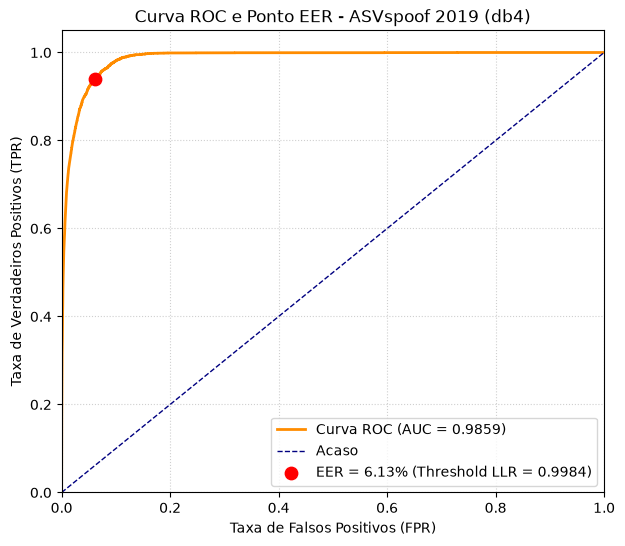

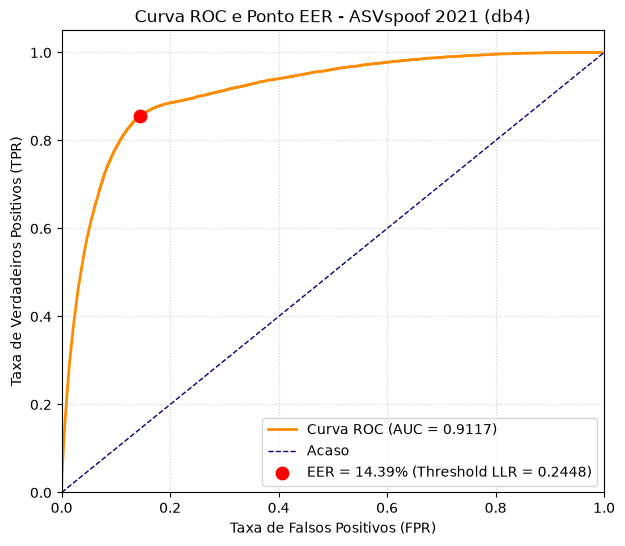


--- Processando Wavelet: db6 ---
Epoch 01/100 | LR: 0.000100 | Train Loss: 0.2416 | Train EER: 0.098391 | Dev Loss: 0.0659 | Dev EER: 0.034116 | ES Counter: 0/10
Epoch 02/100 | LR: 0.000100 | Train Loss: 0.1134 | Train EER: 0.041939 | Dev Loss: 0.0581 | Dev EER: 0.019169 | ES Counter: 0/10
Epoch 03/100 | LR: 0.000100 | Train Loss: 0.0712 | Train EER: 0.025576 | Dev Loss: 0.0213 | Dev EER: 0.006257 | ES Counter: 0/10
Epoch 04/100 | LR: 0.000100 | Train Loss: 0.0650 | Train EER: 0.022099 | Dev Loss: 0.0275 | Dev EER: 0.014128 | ES Counter: 1/10
Epoch 05/100 | LR: 0.000100 | Train Loss: 0.0535 | Train EER: 0.018601 | Dev Loss: 0.0112 | Dev EER: 0.005881 | ES Counter: 0/10
Epoch 06/100 | LR: 0.000100 | Train Loss: 0.0448 | Train EER: 0.015515 | Dev Loss: 0.0542 | Dev EER: 0.014128 | ES Counter: 1/10
Epoch 07/100 | LR: 0.000100 | Train Loss: 0.0437 | Train EER: 0.015884 | Dev Loss: 0.0636 | Dev EER: 0.007541 | ES Counter: 2/10
Epoch 08/100 | LR: 0.000100 | Train Loss: 0.0352 | Train EER: 0

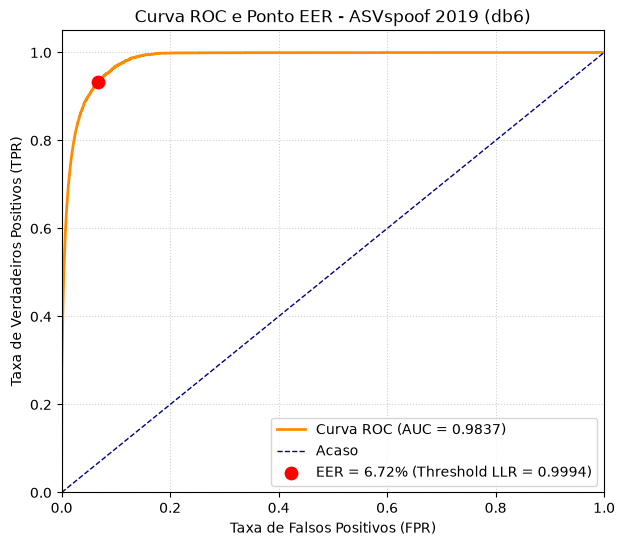

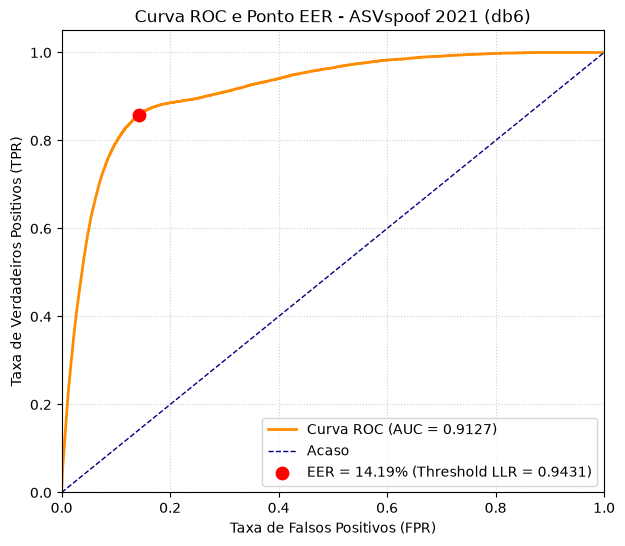


--- Processando Wavelet: db8 ---
Epoch 01/100 | LR: 0.000100 | Train Loss: 0.2563 | Train EER: 0.105432 | Dev Loss: 0.1969 | Dev EER: 0.063920 | ES Counter: 0/10
Epoch 02/100 | LR: 0.000100 | Train Loss: 0.1203 | Train EER: 0.043025 | Dev Loss: 0.0630 | Dev EER: 0.028610 | ES Counter: 0/10
Epoch 03/100 | LR: 0.000100 | Train Loss: 0.0887 | Train EER: 0.033637 | Dev Loss: 0.0330 | Dev EER: 0.011078 | ES Counter: 0/10
Epoch 04/100 | LR: 0.000100 | Train Loss: 0.0665 | Train EER: 0.024011 | Dev Loss: 0.1092 | Dev EER: 0.018793 | ES Counter: 1/10
Epoch 05/100 | LR: 0.000100 | Train Loss: 0.0564 | Train EER: 0.020534 | Dev Loss: 0.0366 | Dev EER: 0.009817 | ES Counter: 0/10
Epoch 06/100 | LR: 0.000100 | Train Loss: 0.0504 | Train EER: 0.018601 | Dev Loss: 0.0163 | Dev EER: 0.009419 | ES Counter: 0/10
Epoch 07/100 | LR: 0.000100 | Train Loss: 0.0411 | Train EER: 0.014016 | Dev Loss: 0.0249 | Dev EER: 0.010989 | ES Counter: 1/10
Epoch 08/100 | LR: 0.000100 | Train Loss: 0.0413 | Train EER: 0

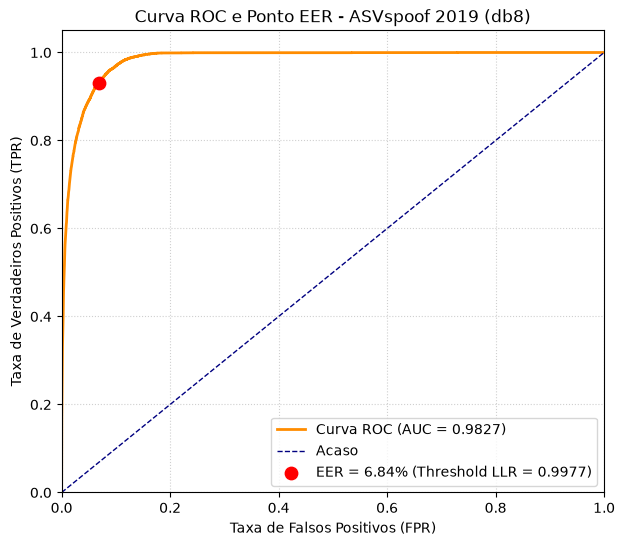

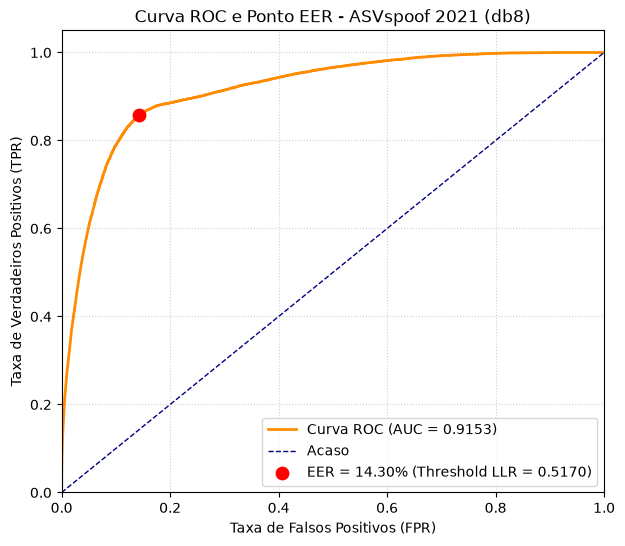


--- Processando Wavelet: db14 ---
Epoch 01/100 | LR: 0.000100 | Train Loss: 0.2604 | Train EER: 0.106562 | Dev Loss: 0.0989 | Dev EER: 0.021579 | ES Counter: 0/10
Epoch 02/100 | LR: 0.000100 | Train Loss: 0.1044 | Train EER: 0.038766 | Dev Loss: 0.0616 | Dev EER: 0.014106 | ES Counter: 0/10
Epoch 03/100 | LR: 0.000100 | Train Loss: 0.0801 | Train EER: 0.029553 | Dev Loss: 0.0329 | Dev EER: 0.016096 | ES Counter: 1/10
Epoch 04/100 | LR: 0.000100 | Train Loss: 0.0579 | Train EER: 0.019774 | Dev Loss: 0.0233 | Dev EER: 0.012559 | ES Counter: 0/10
Epoch 05/100 | LR: 0.000100 | Train Loss: 0.0544 | Train EER: 0.018992 | Dev Loss: 0.0154 | Dev EER: 0.010591 | ES Counter: 0/10
Epoch 06/100 | LR: 0.000100 | Train Loss: 0.0523 | Train EER: 0.018688 | Dev Loss: 0.0282 | Dev EER: 0.008645 | ES Counter: 0/10
Epoch 07/100 | LR: 0.000100 | Train Loss: 0.0419 | Train EER: 0.013559 | Dev Loss: 0.0152 | Dev EER: 0.006588 | ES Counter: 0/10
Epoch 08/100 | LR: 0.000100 | Train Loss: 0.0385 | Train EER: 

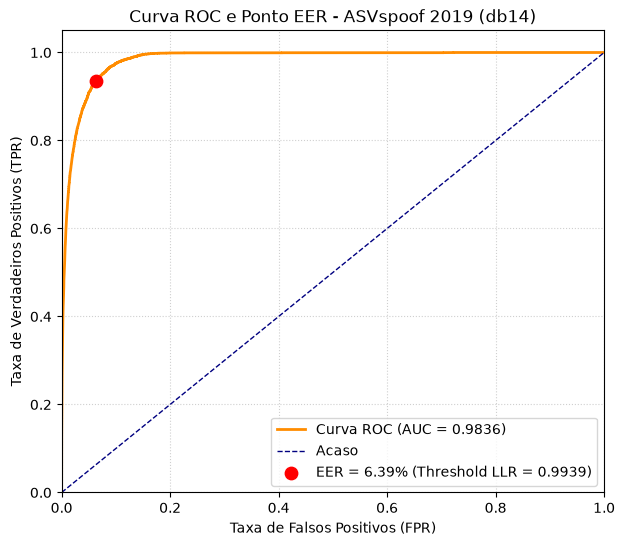

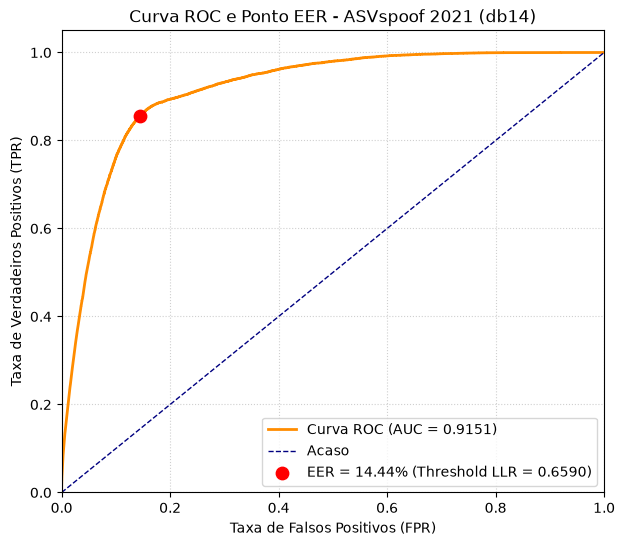


--- Processando Wavelet: db16 ---
Epoch 01/100 | LR: 0.000100 | Train Loss: 0.2660 | Train EER: 0.106171 | Dev Loss: 0.1152 | Dev EER: 0.085942 | ES Counter: 0/10
Epoch 02/100 | LR: 0.000100 | Train Loss: 0.1304 | Train EER: 0.047371 | Dev Loss: 0.0358 | Dev EER: 0.018440 | ES Counter: 0/10
Epoch 03/100 | LR: 0.000100 | Train Loss: 0.0820 | Train EER: 0.029769 | Dev Loss: 0.0385 | Dev EER: 0.020806 | ES Counter: 1/10
Epoch 04/100 | LR: 0.000100 | Train Loss: 0.0730 | Train EER: 0.025576 | Dev Loss: 0.0471 | Dev EER: 0.020385 | ES Counter: 2/10
Epoch 05/100 | LR: 0.000100 | Train Loss: 0.0540 | Train EER: 0.019774 | Dev Loss: 0.0470 | Dev EER: 0.017246 | ES Counter: 0/10
Epoch 06/100 | LR: 0.000100 | Train Loss: 0.0473 | Train EER: 0.017862 | Dev Loss: 0.0252 | Dev EER: 0.012161 | ES Counter: 0/10
Epoch 07/100 | LR: 0.000100 | Train Loss: 0.0536 | Train EER: 0.019752 | Dev Loss: 0.0960 | Dev EER: 0.012491 | ES Counter: 1/10
Epoch 08/100 | LR: 0.000100 | Train Loss: 0.0397 | Train EER: 

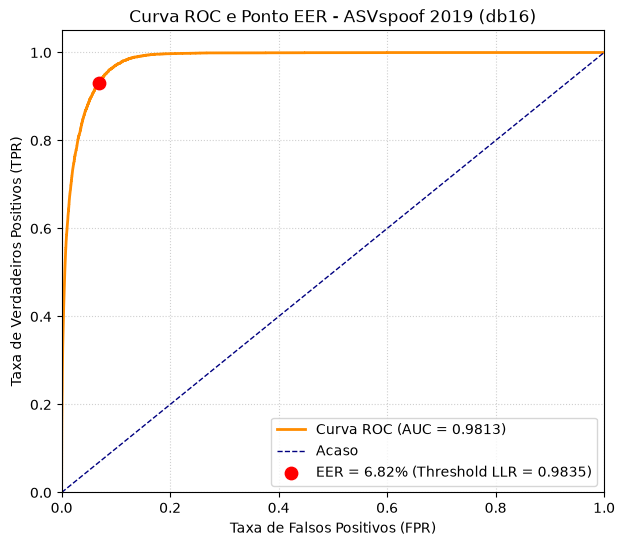

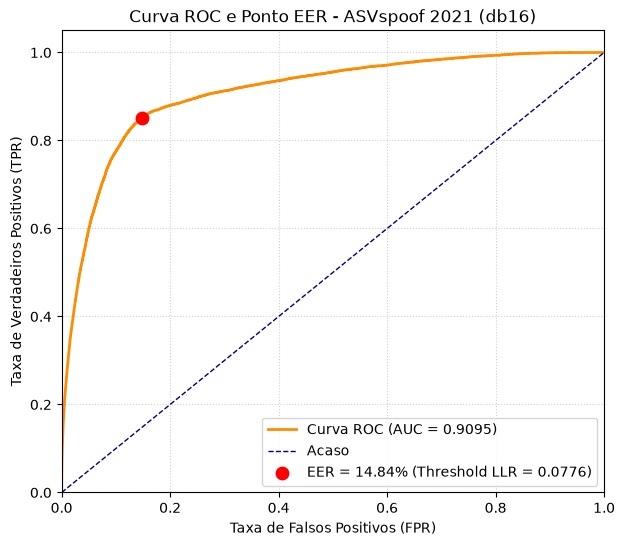


--- Processando Wavelet: db18 ---
Epoch 01/100 | LR: 0.000100 | Train Loss: 0.2785 | Train EER: 0.119796 | Dev Loss: 0.1116 | Dev EER: 0.026289 | ES Counter: 0/10
Epoch 02/100 | LR: 0.000100 | Train Loss: 0.1180 | Train EER: 0.043719 | Dev Loss: 0.0474 | Dev EER: 0.016517 | ES Counter: 0/10
Epoch 03/100 | LR: 0.000100 | Train Loss: 0.0880 | Train EER: 0.031378 | Dev Loss: 0.0360 | Dev EER: 0.019258 | ES Counter: 1/10
Epoch 04/100 | LR: 0.000100 | Train Loss: 0.0689 | Train EER: 0.023730 | Dev Loss: 0.0679 | Dev EER: 0.018131 | ES Counter: 2/10
Epoch 05/100 | LR: 0.000100 | Train Loss: 0.0536 | Train EER: 0.018209 | Dev Loss: 0.0291 | Dev EER: 0.014173 | ES Counter: 0/10
Epoch 06/100 | LR: 0.000100 | Train Loss: 0.0535 | Train EER: 0.018601 | Dev Loss: 0.0643 | Dev EER: 0.012934 | ES Counter: 0/10
Epoch 07/100 | LR: 0.000100 | Train Loss: 0.0454 | Train EER: 0.015493 | Dev Loss: 0.0323 | Dev EER: 0.016405 | ES Counter: 1/10
Epoch 08/100 | LR: 0.000100 | Train Loss: 0.0455 | Train EER: 

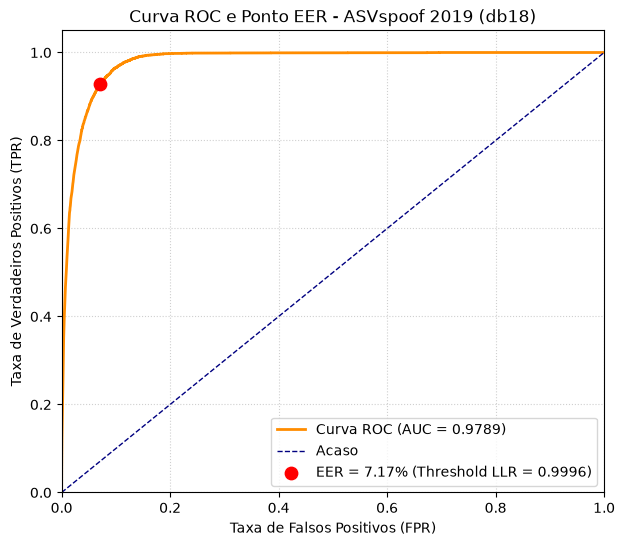

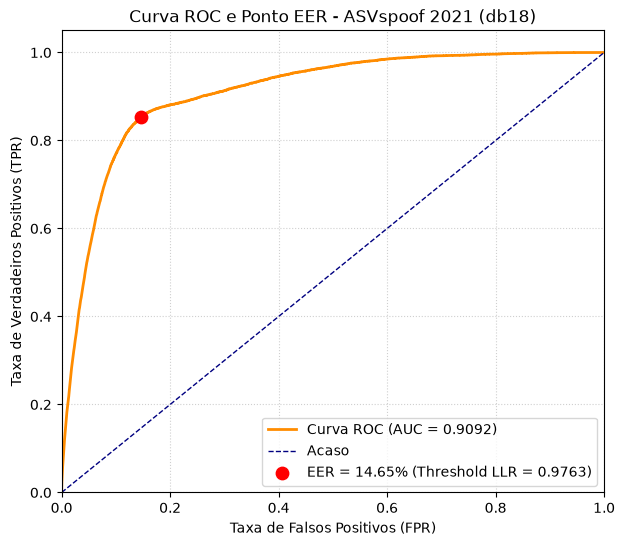


--- Processando Wavelet: db24 ---
Epoch 01/100 | LR: 0.000100 | Train Loss: 0.2650 | Train EER: 0.108518 | Dev Loss: 0.3264 | Dev EER: 0.042385 | ES Counter: 0/10
Epoch 02/100 | LR: 0.000100 | Train Loss: 0.1201 | Train EER: 0.044959 | Dev Loss: 0.1250 | Dev EER: 0.019146 | ES Counter: 0/10
Epoch 03/100 | LR: 0.000100 | Train Loss: 0.0865 | Train EER: 0.030226 | Dev Loss: 0.1464 | Dev EER: 0.020806 | ES Counter: 1/10
Epoch 04/100 | LR: 0.000100 | Train Loss: 0.0734 | Train EER: 0.027575 | Dev Loss: 0.0896 | Dev EER: 0.019191 | ES Counter: 2/10
Epoch 05/100 | LR: 0.000100 | Train Loss: 0.0601 | Train EER: 0.022403 | Dev Loss: 0.0367 | Dev EER: 0.011785 | ES Counter: 0/10
Epoch 06/100 | LR: 0.000100 | Train Loss: 0.0558 | Train EER: 0.019405 | Dev Loss: 0.0233 | Dev EER: 0.011785 | ES Counter: 1/10
Epoch 07/100 | LR: 0.000100 | Train Loss: 0.0496 | Train EER: 0.017449 | Dev Loss: 0.0242 | Dev EER: 0.006722 | ES Counter: 0/10
Epoch 08/100 | LR: 0.000100 | Train Loss: 0.0412 | Train EER: 

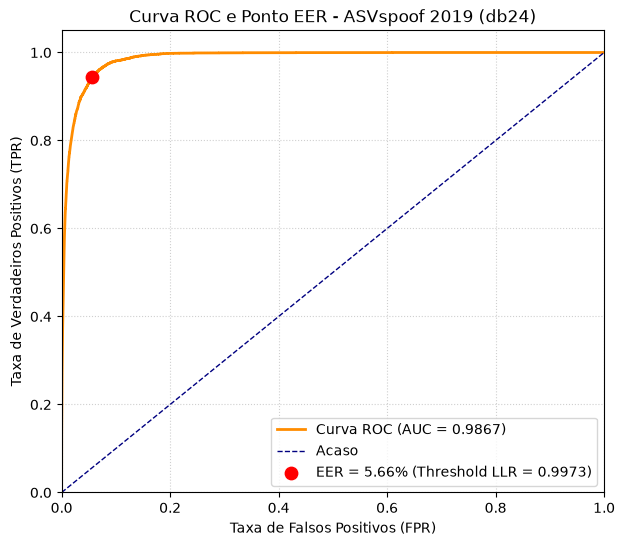

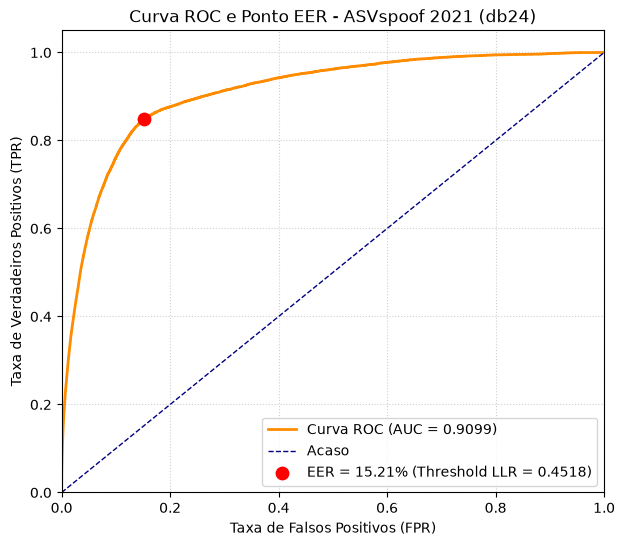


--- Processando Wavelet: db26 ---
Epoch 01/100 | LR: 0.000100 | Train Loss: 0.2679 | Train EER: 0.110843 | Dev Loss: 0.1549 | Dev EER: 0.036414 | ES Counter: 0/10
Epoch 02/100 | LR: 0.000100 | Train Loss: 0.1199 | Train EER: 0.047306 | Dev Loss: 0.0415 | Dev EER: 0.020408 | ES Counter: 0/10
Epoch 03/100 | LR: 0.000100 | Train Loss: 0.0910 | Train EER: 0.034419 | Dev Loss: 0.0435 | Dev EER: 0.018440 | ES Counter: 0/10
Epoch 04/100 | LR: 0.000100 | Train Loss: 0.0702 | Train EER: 0.024859 | Dev Loss: 0.0369 | Dev EER: 0.010989 | ES Counter: 0/10
Epoch 05/100 | LR: 0.000100 | Train Loss: 0.0597 | Train EER: 0.019774 | Dev Loss: 0.0440 | Dev EER: 0.016494 | ES Counter: 1/10
Epoch 06/100 | LR: 0.000100 | Train Loss: 0.0585 | Train EER: 0.020578 | Dev Loss: 0.0205 | Dev EER: 0.009419 | ES Counter: 0/10
Epoch 07/100 | LR: 0.000100 | Train Loss: 0.0515 | Train EER: 0.018513 | Dev Loss: 0.1114 | Dev EER: 0.036947 | ES Counter: 1/10
Epoch 08/100 | LR: 0.000100 | Train Loss: 0.0430 | Train EER: 

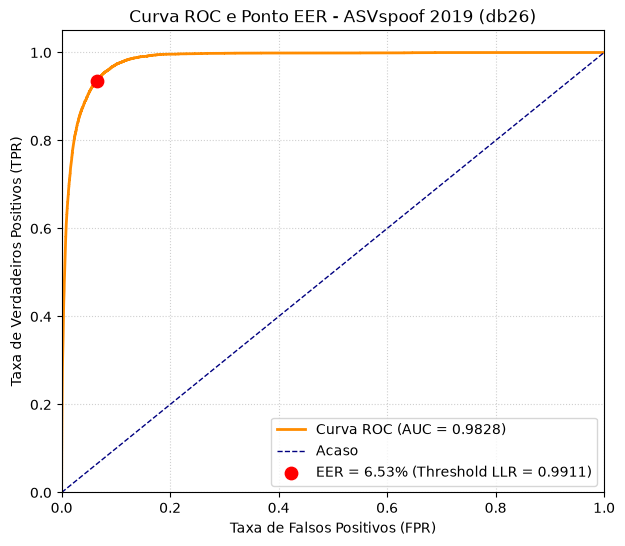

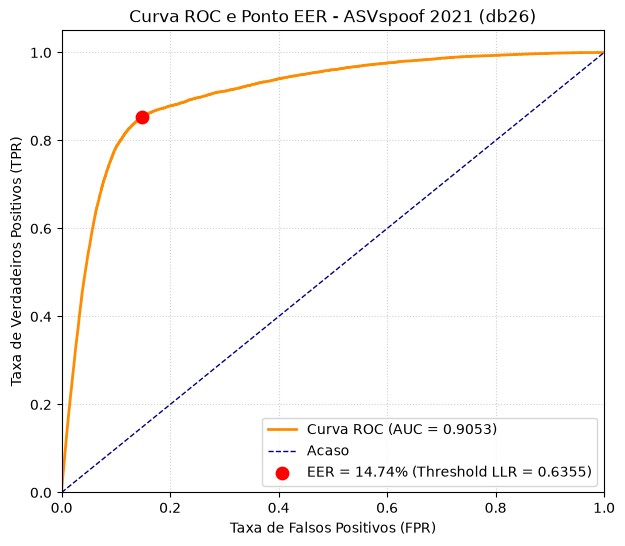


--- Processando Wavelet: db28 ---
Epoch 01/100 | LR: 0.000100 | Train Loss: 0.2790 | Train EER: 0.115906 | Dev Loss: 0.1096 | Dev EER: 0.042430 | ES Counter: 0/10
Epoch 02/100 | LR: 0.000100 | Train Loss: 0.1420 | Train EER: 0.052716 | Dev Loss: 0.0563 | Dev EER: 0.020077 | ES Counter: 0/10
Epoch 03/100 | LR: 0.000100 | Train Loss: 0.0895 | Train EER: 0.031008 | Dev Loss: 0.1111 | Dev EER: 0.025868 | ES Counter: 1/10
Epoch 04/100 | LR: 0.000100 | Train Loss: 0.0806 | Train EER: 0.030226 | Dev Loss: 0.0304 | Dev EER: 0.015300 | ES Counter: 0/10
Epoch 05/100 | LR: 0.000100 | Train Loss: 0.0575 | Train EER: 0.020534 | Dev Loss: 0.0398 | Dev EER: 0.014880 | ES Counter: 0/10
Epoch 06/100 | LR: 0.000100 | Train Loss: 0.0604 | Train EER: 0.023163 | Dev Loss: 0.1493 | Dev EER: 0.049063 | ES Counter: 1/10
Epoch 07/100 | LR: 0.000100 | Train Loss: 0.0546 | Train EER: 0.019383 | Dev Loss: 0.0382 | Dev EER: 0.009374 | ES Counter: 0/10
Epoch 08/100 | LR: 0.000100 | Train Loss: 0.0513 | Train EER: 

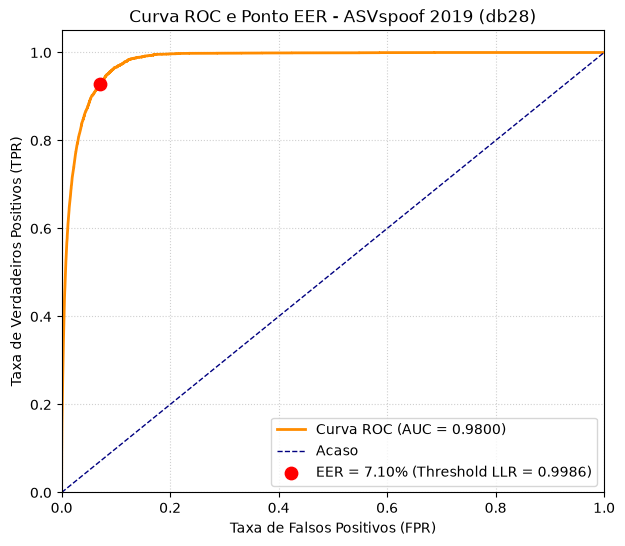

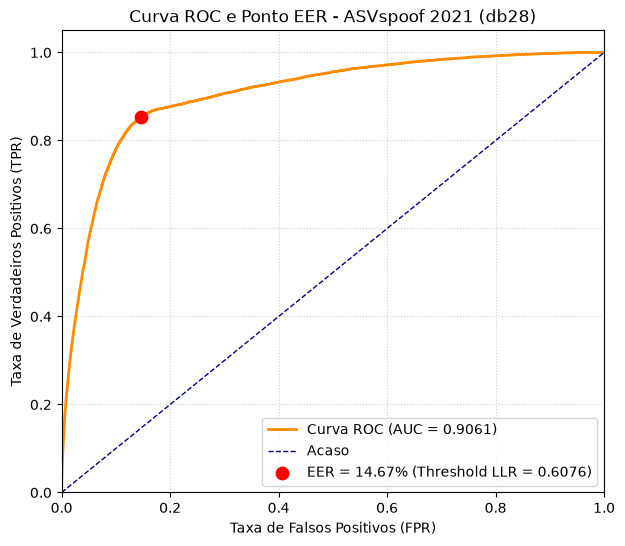


--- Processando Wavelet: db34 ---
Epoch 01/100 | LR: 0.000100 | Train Loss: 0.2882 | Train EER: 0.121317 | Dev Loss: 0.1836 | Dev EER: 0.040417 | ES Counter: 0/10
Epoch 02/100 | LR: 0.000100 | Train Loss: 0.1293 | Train EER: 0.044220 | Dev Loss: 0.2265 | Dev EER: 0.024343 | ES Counter: 0/10
Epoch 03/100 | LR: 0.000100 | Train Loss: 0.0894 | Train EER: 0.033289 | Dev Loss: 0.0669 | Dev EER: 0.016051 | ES Counter: 0/10
Epoch 04/100 | LR: 0.000100 | Train Loss: 0.0717 | Train EER: 0.026380 | Dev Loss: 0.0209 | Dev EER: 0.011387 | ES Counter: 0/10
Epoch 05/100 | LR: 0.000100 | Train Loss: 0.0670 | Train EER: 0.025185 | Dev Loss: 0.0320 | Dev EER: 0.018350 | ES Counter: 1/10
Epoch 06/100 | LR: 0.000100 | Train Loss: 0.0518 | Train EER: 0.017774 | Dev Loss: 0.0486 | Dev EER: 0.026665 | ES Counter: 2/10
Epoch 07/100 | LR: 0.000100 | Train Loss: 0.0515 | Train EER: 0.017449 | Dev Loss: 0.0301 | Dev EER: 0.016870 | ES Counter: 3/10
Epoch 08/100 | LR: 0.000100 | Train Loss: 0.0432 | Train EER: 

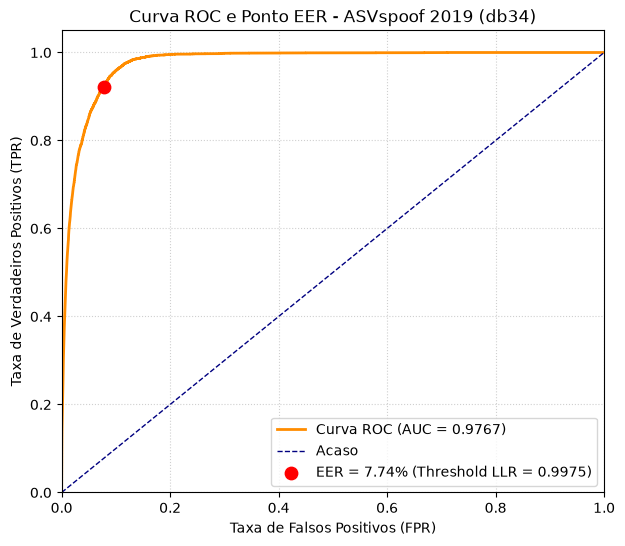

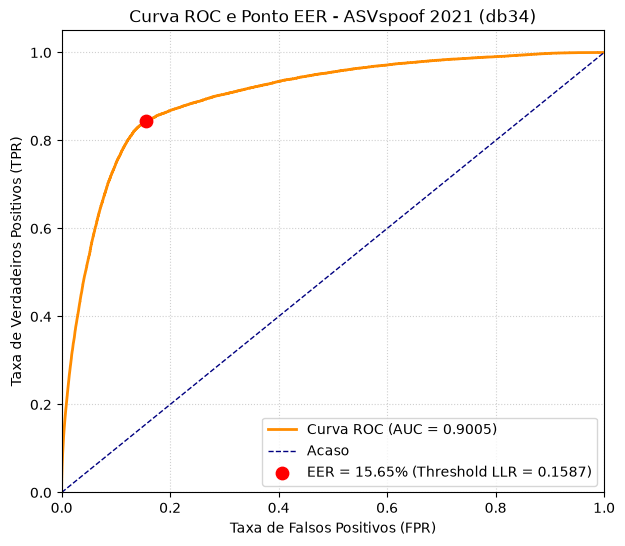


--- Processando Wavelet: db36 ---
Epoch 01/100 | LR: 0.000100 | Train Loss: 0.2730 | Train EER: 0.117361 | Dev Loss: 0.1566 | Dev EER: 0.046276 | ES Counter: 0/10
Epoch 02/100 | LR: 0.000100 | Train Loss: 0.1344 | Train EER: 0.048783 | Dev Loss: 0.1119 | Dev EER: 0.040462 | ES Counter: 0/10
Epoch 03/100 | LR: 0.000100 | Train Loss: 0.0945 | Train EER: 0.034788 | Dev Loss: 0.0433 | Dev EER: 0.016494 | ES Counter: 0/10
Epoch 04/100 | LR: 0.000100 | Train Loss: 0.0766 | Train EER: 0.027510 | Dev Loss: 0.0282 | Dev EER: 0.015721 | ES Counter: 0/10
Epoch 05/100 | LR: 0.000100 | Train Loss: 0.0669 | Train EER: 0.024815 | Dev Loss: 0.2317 | Dev EER: 0.021579 | ES Counter: 1/10
Epoch 06/100 | LR: 0.000100 | Train Loss: 0.0572 | Train EER: 0.020165 | Dev Loss: 0.0307 | Dev EER: 0.010989 | ES Counter: 0/10
Epoch 07/100 | LR: 0.000100 | Train Loss: 0.0455 | Train EER: 0.015884 | Dev Loss: 0.0452 | Dev EER: 0.006302 | ES Counter: 0/10
Epoch 08/100 | LR: 0.000100 | Train Loss: 0.0461 | Train EER: 

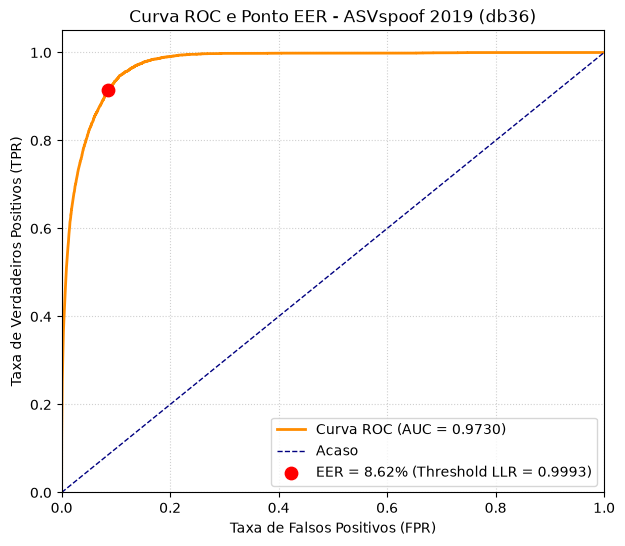

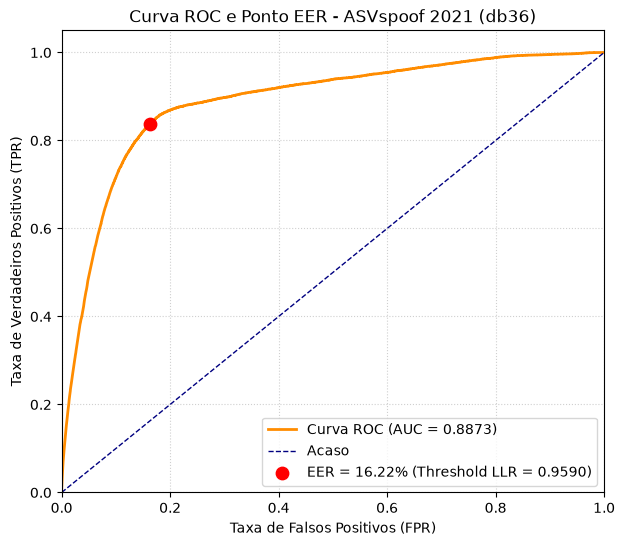


--- Processando Wavelet: db38 ---
Epoch 01/100 | LR: 0.000100 | Train Loss: 0.2688 | Train EER: 0.115884 | Dev Loss: 0.2252 | Dev EER: 0.059255 | ES Counter: 0/10
Epoch 02/100 | LR: 0.000100 | Train Loss: 0.1363 | Train EER: 0.053433 | Dev Loss: 0.1087 | Dev EER: 0.025560 | ES Counter: 0/10
Epoch 03/100 | LR: 0.000100 | Train Loss: 0.0874 | Train EER: 0.030617 | Dev Loss: 0.0488 | Dev EER: 0.023615 | ES Counter: 0/10
Epoch 04/100 | LR: 0.000100 | Train Loss: 0.0738 | Train EER: 0.026815 | Dev Loss: 0.0259 | Dev EER: 0.012957 | ES Counter: 0/10
Epoch 05/100 | LR: 0.000100 | Train Loss: 0.0641 | Train EER: 0.022490 | Dev Loss: 0.0280 | Dev EER: 0.013730 | ES Counter: 1/10
Epoch 06/100 | LR: 0.000100 | Train Loss: 0.0563 | Train EER: 0.022011 | Dev Loss: 0.0149 | Dev EER: 0.009021 | ES Counter: 0/10
Epoch 07/100 | LR: 0.000100 | Train Loss: 0.0506 | Train EER: 0.018992 | Dev Loss: 0.0620 | Dev EER: 0.019920 | ES Counter: 1/10
Epoch 08/100 | LR: 0.000100 | Train Loss: 0.0461 | Train EER: 

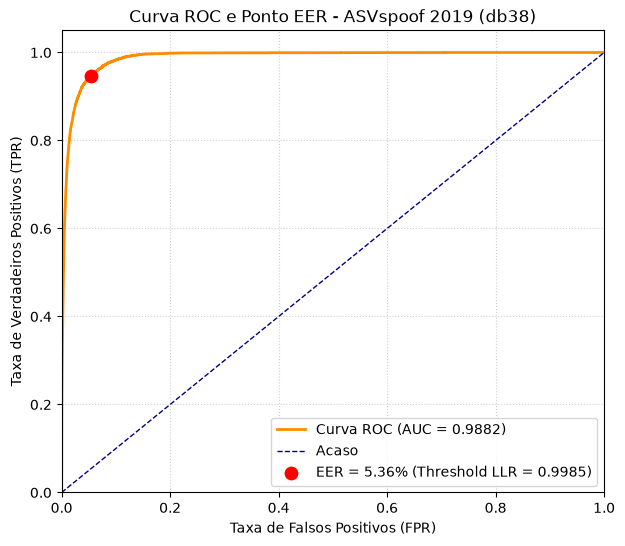

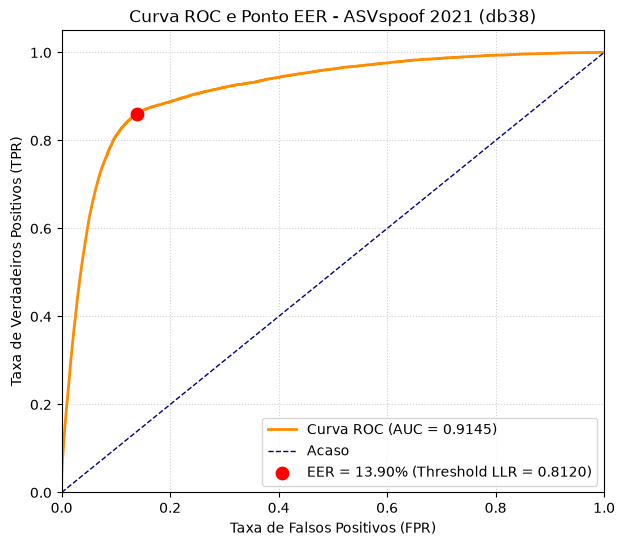


Resultados salvos com sucesso!
 - ../results/v2.5/results_validation/wavelet_results.csv
 - ../results/v2.5/results_validation/training_<wavelet>.csv para cada wavelet


In [53]:
results = []

for wavelet_family in WAVELET_FAMILIES:
    print(f"\n--- Processando Wavelet: {wavelet_family} ---")

    model, criterion, history, best_model_state = setup_model(wavelet_family)

    model.load_state_dict(best_model_state)
    model.to(device)
    model.eval()

    history_df = pd.DataFrame(history)
    history_df.to_csv(
        f"../results/v2.5/results_validation/training_{wavelet_family}.csv",
        index=False
    )

    results.append(evaluate_asv_2019(model, eval_loader, criterion, device, wavelet_family))
    results.append(evaluate_asv_2021(model, eval_2021_loader, criterion, device, wavelet_family))
    

results_df = pd.DataFrame(results)

results_df.to_csv(
    "../results/v2.5/results_validation/wavelet_results.csv",
    index=False
)

print("\nResultados salvos com sucesso!")
print(" - ../results/v2.5/results_validation/wavelet_results.csv")
print(" - ../results/v2.5/results_validation/training_<wavelet>.csv para cada wavelet")

In [54]:
def conv_block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
    )


class AverageCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            conv_block(1, 32),
            conv_block(32, 32),
            nn.AvgPool2d(kernel_size=2),

            conv_block(32, 64),
            conv_block(64, 64),
            nn.AvgPool2d(kernel_size=2),

            conv_block(64, 128),
            conv_block(128, 128),
            nn.AvgPool2d(kernel_size=2),

            conv_block(128, 256),
            conv_block(256, 256),
            nn.Dropout2d(0.1),
        )

        self.classifier = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        x = self.features(x)
        x = x.mean(dim=2)
        x = torch.cat([x.mean(dim=2), x.std(dim=2)], dim=1)
        return self.classifier(x)

In [55]:
def setup_model_average():
    model = AverageCNN().to(device)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-4,
        weight_decay=1e-4
    )

    scheduler = ReduceLROnPlateau(
        optimizer,
        mode='min',
        factor=0.1,
        patience=5,
        threshold=1e-4,
        min_lr=1e-6
    )

    history, best_model_state = run_model(model, criterion, optimizer, scheduler)
    return model, criterion, history, best_model_state

Epoch 01/100 | LR: 0.000100 | Train Loss: 0.2376 | Train EER: 0.093416 | Dev Loss: 0.0357 | Dev EER: 0.021204 | ES Counter: 0/10
Epoch 02/100 | LR: 0.000100 | Train Loss: 0.0914 | Train EER: 0.033724 | Dev Loss: 0.1730 | Dev EER: 0.021579 | ES Counter: 1/10
Epoch 03/100 | LR: 0.000100 | Train Loss: 0.0769 | Train EER: 0.027053 | Dev Loss: 0.0212 | Dev EER: 0.008600 | ES Counter: 0/10
Epoch 04/100 | LR: 0.000100 | Train Loss: 0.0533 | Train EER: 0.020513 | Dev Loss: 0.0333 | Dev EER: 0.009021 | ES Counter: 1/10
Epoch 05/100 | LR: 0.000100 | Train Loss: 0.0444 | Train EER: 0.016667 | Dev Loss: 0.0064 | Dev EER: 0.003560 | ES Counter: 0/10
Epoch 06/100 | LR: 0.000100 | Train Loss: 0.0398 | Train EER: 0.015493 | Dev Loss: 0.0113 | Dev EER: 0.005506 | ES Counter: 1/10
Epoch 07/100 | LR: 0.000100 | Train Loss: 0.0346 | Train EER: 0.012408 | Dev Loss: 0.0156 | Dev EER: 0.003162 | ES Counter: 0/10
Epoch 08/100 | LR: 0.000100 | Train Loss: 0.0333 | Train EER: 0.012320 | Dev Loss: 0.0067 | Dev E

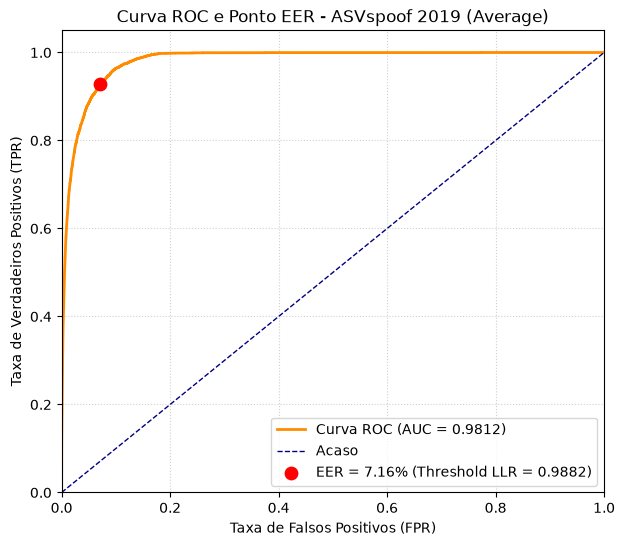

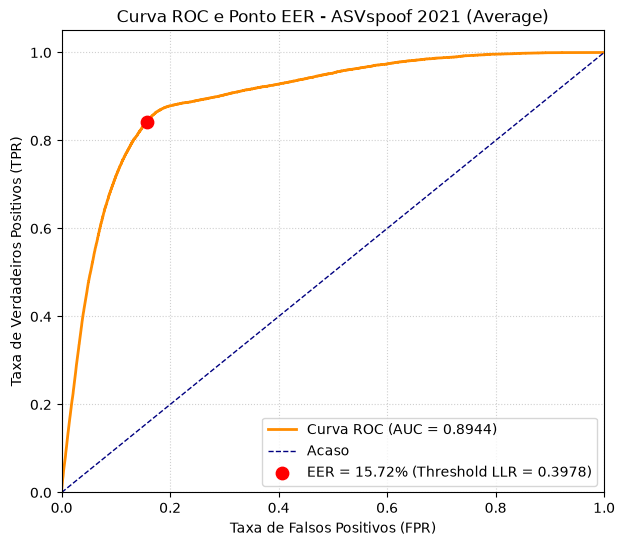

In [56]:
results = []

model, criterion, history, best_model_state = setup_model_average()

model.load_state_dict(best_model_state)
model.to(device)
model.eval()

history_df = pd.DataFrame(history)
history_df.to_csv(
    f"../results/v2.5/results_validation/training_average.csv",
    index=False
)

results.append(evaluate_asv_2019(model, eval_loader, criterion, device, "Average"))
results.append(evaluate_asv_2021(model, eval_2021_loader, criterion, device, "Average"))


results_df = pd.DataFrame(results)

results_df.to_csv(
    "../results/v2.5/results_validation/average_results_average.csv",
    index=False
)

In [57]:
def conv_block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
    )


class MaxCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            conv_block(1, 32),
            conv_block(32, 32),
            nn.MaxPool2d(kernel_size=2),

            conv_block(32, 64),
            conv_block(64, 64),
            nn.MaxPool2d(kernel_size=2),

            conv_block(64, 128),
            conv_block(128, 128),
            nn.MaxPool2d(kernel_size=2),

            conv_block(128, 256),
            conv_block(256, 256),
            nn.Dropout2d(0.1),
        )

        self.classifier = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(128, 2),
        )

    def forward(self, x):
        x = self.features(x)
        x = x.mean(dim=2)
        x = torch.cat([x.mean(dim=2), x.std(dim=2)], dim=1)
        return self.classifier(x)

In [58]:
def setup_model_max():
    model = MaxCNN().to(device)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-4,
        weight_decay=1e-4
    )

    scheduler = ReduceLROnPlateau(
        optimizer,
        mode='min',
        factor=0.1,
        patience=5,
        threshold=1e-4,
        min_lr=1e-6
    )

    history, best_model_state = run_model(model, criterion, optimizer, scheduler)
    return model, criterion, history, best_model_state

Epoch 01/100 | LR: 0.000100 | Train Loss: 0.2425 | Train EER: 0.099675 | Dev Loss: 0.2369 | Dev EER: 0.010591 | ES Counter: 0/10
Epoch 02/100 | LR: 0.000100 | Train Loss: 0.0911 | Train EER: 0.032639 | Dev Loss: 0.0724 | Dev EER: 0.014482 | ES Counter: 1/10
Epoch 03/100 | LR: 0.000100 | Train Loss: 0.0598 | Train EER: 0.020926 | Dev Loss: 0.0205 | Dev EER: 0.005949 | ES Counter: 0/10
Epoch 04/100 | LR: 0.000100 | Train Loss: 0.0523 | Train EER: 0.018122 | Dev Loss: 0.0130 | Dev EER: 0.006767 | ES Counter: 1/10
Epoch 05/100 | LR: 0.000100 | Train Loss: 0.0395 | Train EER: 0.013515 | Dev Loss: 0.2746 | Dev EER: 0.018064 | ES Counter: 2/10
Epoch 06/100 | LR: 0.000100 | Train Loss: 0.0382 | Train EER: 0.013212 | Dev Loss: 0.1004 | Dev EER: 0.010125 | ES Counter: 3/10
Epoch 07/100 | LR: 0.000100 | Train Loss: 0.0372 | Train EER: 0.013603 | Dev Loss: 0.0204 | Dev EER: 0.011785 | ES Counter: 4/10
Epoch 08/100 | LR: 0.000100 | Train Loss: 0.0320 | Train EER: 0.010843 | Dev Loss: 0.0075 | Dev E

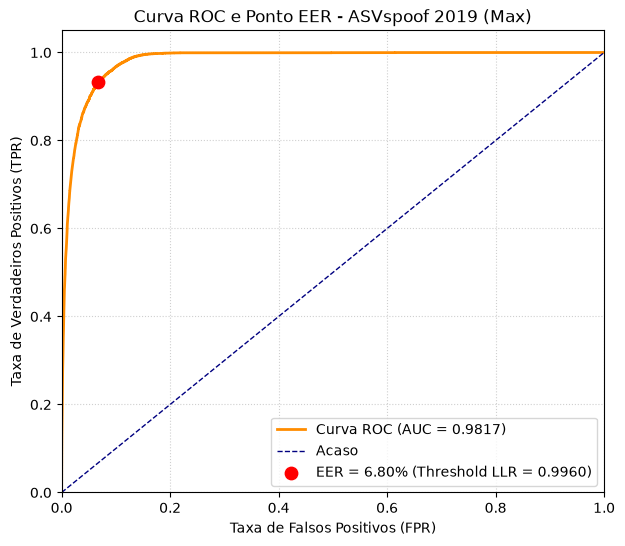

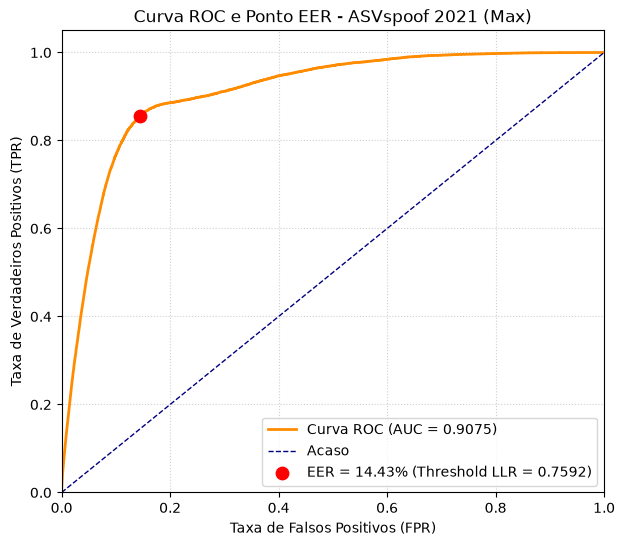

In [59]:
results = []

model, criterion, history, best_model_state = setup_model_max()

model.load_state_dict(best_model_state)
model.to(device)
model.eval()

history_df = pd.DataFrame(history)
history_df.to_csv(
    f"../results/v2.5/results_validation/training_max.csv",
    index=False
)

results.append(evaluate_asv_2019(model, eval_loader, criterion, device, "Max"))
results.append(evaluate_asv_2021(model, eval_2021_loader, criterion, device, "Max"))


results_df = pd.DataFrame(results)

results_df.to_csv(
    "../results/v2.5/results_validation/average_results_max.csv",
    index=False
)